# Steel Plate Fault Lens &ndash; Model Training Notebook

**AIML ZG565 Machine Learning &ndash; Assignment 2 &nbsp;|&nbsp;
BITS ID: 2026AJ05442**

This notebook trains and compares five classifiers on the UCI **Steel Plates
Faults** dataset. It then saves the trained models into `model/`, which the
Streamlit app (`app.py`) loads. It does the same work as `train_models.py`,
but step by step with explanations and plots.

**Steps**
1. Load the data and turn the 7 one-hot fault columns into one label
2. Explore the data (class balance, correlations, skewness)
3. Stratified 80/20 train/test split and export `test_data.csv`
4. Tune and train 5 models: Logistic Regression, Decision Tree, kNN,
   Gaussian Naive Bayes, SVM
5. Evaluate on the test split with Accuracy, AUC, Precision, Recall, F1
   and MCC
6. Confusion matrices and classification report
7. Save the models and check that the saved files give the same results

> Run it from the repository root (the folder that contains `data/` and
> `app.py`) using **Kernel → Restart & Run All**.

## 1. Setup and imports

In [1]:
import json
import platform
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)

print("Python      :", platform.python_version())
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python      : 3.14.0
numpy       : 2.5.4
pandas      : 3.1.1
scikit-learn: 1.9.1


In [2]:
RAW_CSV = Path("data") / "steel_plates_faults_raw.csv"
ARTIFACT_DIR = Path("model")
HOLDOUT_CSV = Path("test_data.csv")

SEED = 2026
HOLDOUT_FRACTION = 0.20
TARGET_COLUMN = "fault_type"
FAULT_FLAG_COLUMNS = [
    "Pastry", "Z_Scratch", "K_Scatch", "Stains",
    "Dirtiness", "Bumps", "Other_Faults",
]

assert RAW_CSV.exists(), (
    "data/steel_plates_faults_raw.csv not found - start Jupyter from the "
    "repository root folder."
)

## 2. Load the dataset

The raw UCI table has **27 numeric features** and **7 one-hot columns**, one
per fault type. Every plate has exactly one fault, so we turn the 7 flags
into a single text label `fault_type`.

In [3]:
plates = pd.read_csv(RAW_CSV)
print("Raw shape:", plates.shape)

flag_sum = plates[FAULT_FLAG_COLUMNS].sum(axis=1)
assert (flag_sum == 1).all(), "each plate must have exactly one fault"

plates[TARGET_COLUMN] = plates[FAULT_FLAG_COLUMNS].idxmax(axis=1)
plates = plates.drop(columns=FAULT_FLAG_COLUMNS)
feature_names = [c for c in plates.columns if c != TARGET_COLUMN]

print("After merging labels:", plates.shape)
print("Number of features :", len(feature_names))
plates.head()

Raw shape: (1941, 34)
After merging labels: (1941, 28)
Number of features : 27


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,fault_type
0,42,50,270900,270944,267,17,44,24220,76,108,1687,1,0,80,0.0498,0.2415,0.1818,0.0047,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,Pastry
1,645,651,2538079,2538108,108,10,30,11397,84,123,1687,1,0,80,0.7647,0.3793,0.2069,0.0036,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,Pastry
2,829,835,1553913,1553931,71,8,19,7972,99,125,1623,1,0,100,0.9710,0.3426,0.3333,0.0037,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,Pastry
3,853,860,369370,369415,176,13,45,18996,99,126,1353,0,1,290,0.7287,0.4413,0.1556,0.0052,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,Pastry
4,1289,1306,498078,498335,2409,60,260,246930,37,126,1353,0,1,185,0.0695,0.4486,0.0662,0.0126,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,Pastry


## 3. Exploratory data analysis

In [4]:
print("Missing values :", int(plates.isna().sum().sum()))
print("Duplicate rows :", int(plates.duplicated().sum()))
plates[feature_names].describe().T.round(3)

Missing values : 0
Duplicate rows : 0


,count,mean,std,min,25%,50%,75%,max
X_Minimum,1941.0,571.136,520.691,0.000,51.000,435.000,1053.000,1.705000e+03
X_Maximum,1941.0,617.964,497.627,4.000,192.000,467.000,1072.000,1.713000e+03
Y_Minimum,1941.0,1650684.868,1774578.415,6712.000,471253.000,1204128.000,2183073.000,1.298766e+07
Y_Maximum,1941.0,1650738.705,1774590.089,6724.000,471281.000,1204136.000,2183084.000,1.298769e+07
Pixels_Areas,1941.0,1893.878,5168.460,2.000,84.000,174.000,822.000,1.526550e+05
X_Perimeter,1941.0,111.855,301.209,2.000,15.000,26.000,84.000,1.044900e+04
Y_Perimeter,1941.0,82.966,426.483,1.000,13.000,25.000,83.000,1.815200e+04
Sum_of_Luminosity,1941.0,206312.148,512293.588,250.000,9522.000,19202.000,83011.000,1.159141e+07
Minimum_of_Luminosity,1941.0,84.549,32.134,0.000,63.000,90.000,106.000,2.030000e+02
Maximum_of_Luminosity,1941.0,130.194,18.691,37.000,124.000,127.000,140.000,2.530000e+02


              count  share_%
fault_type                  
Other_Faults    673     34.7
Bumps           402     20.7
K_Scatch        391     20.1
Z_Scratch       190      9.8
Pastry          158      8.1
Stains           72      3.7
Dirtiness        55      2.8
Imbalance ratio (largest / smallest): 12.2


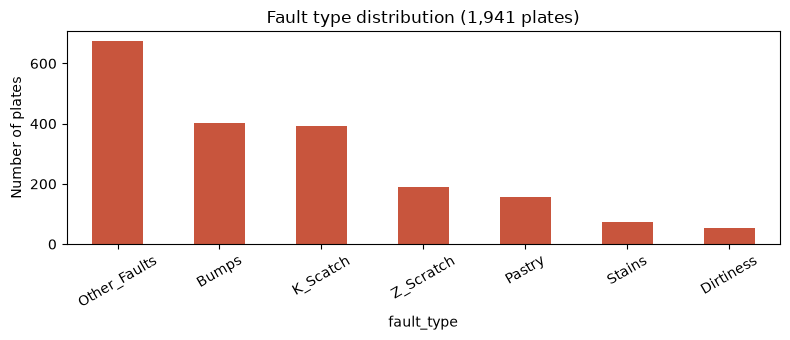

In [5]:
class_counts = plates[TARGET_COLUMN].value_counts()
class_table = pd.DataFrame({
    "count": class_counts,
    "share_%": (100 * class_counts / len(plates)).round(1),
})
print(class_table)
print("Imbalance ratio (largest / smallest):",
      round(class_counts.max() / class_counts.min(), 1))

fig, ax = plt.subplots(figsize=(8, 3.5))
class_counts.plot.bar(ax=ax, color="#C8553D")
ax.set_title("Fault type distribution (1,941 plates)")
ax.set_ylabel("Number of plates")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

The classes are **imbalanced**: `Other_Faults` has about 12 times as many
plates as `Dirtiness`. Because of this we report Precision, Recall and F1 as
**macro averages**, so every fault type counts equally. We also use a
**stratified** split so the test set keeps the same class proportions.

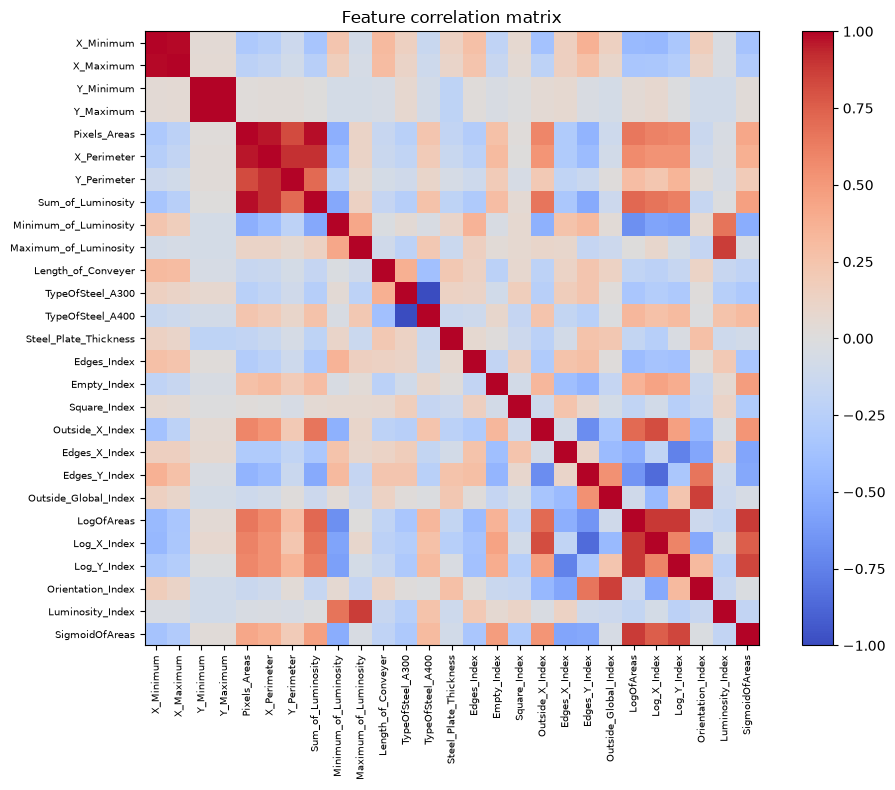

Feature pairs with |r| > 0.9: 7

Most skewed features:
Y_Perimeter          39.3
X_Perimeter          21.5
Pixels_Areas         14.1
Sum_of_Luminosity     7.7
Outside_X_Index       5.2
dtype: float64


In [6]:
corr = plates[feature_names].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(feature_names)), feature_names, rotation=90,
              fontsize=7)
ax.set_yticks(range(len(feature_names)), feature_names, fontsize=7)
ax.set_title("Feature correlation matrix")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

abs_corr = corr.abs().to_numpy().copy()
np.fill_diagonal(abs_corr, 0)
print("Feature pairs with |r| > 0.9:", int((abs_corr > 0.9).sum() / 2))
print("\nMost skewed features:")
print(plates[feature_names].skew().abs()
      .sort_values(ascending=False).head(5).round(1))

**What the EDA tells us**
- Several features are almost copies of each other (7 pairs have
  |r| > 0.9), and some are very skewed. This breaks the "independent,
  normally distributed features" assumption of Gaussian Naive Bayes.
- Feature ranges differ by several orders of magnitude, for example
  `Sum_of_Luminosity` against the 0–1 indices. Distance-based (kNN) and
  margin-based (SVM, Logistic Regression) models therefore need a
  **StandardScaler**. The Decision Tree does not.

## 4. Encode labels, split the data and export `test_data.csv`

In [7]:
fault_encoder = LabelEncoder().fit(plates[TARGET_COLUMN])
X = plates[feature_names]
y = fault_encoder.transform(plates[TARGET_COLUMN])
class_ids = np.arange(len(fault_encoder.classes_))
print("Class id mapping:",
      dict(zip(fault_encoder.classes_, class_ids.tolist())))

X_fit, X_hold, y_fit, y_hold = train_test_split(
    X, y, test_size=HOLDOUT_FRACTION, stratify=y, random_state=SEED
)
print("Train rows:", len(X_fit), "| Test rows:", len(X_hold))

holdout_frame = X_hold.copy()
holdout_frame[TARGET_COLUMN] = fault_encoder.inverse_transform(y_hold)
holdout_frame.to_csv(HOLDOUT_CSV, index=False)
print("Saved", HOLDOUT_CSV, "->", holdout_frame.shape)

Class id mapping: {'Bumps': 0, 'Dirtiness': 1, 'K_Scatch': 2, 'Other_Faults': 3, 'Pastry': 4, 'Stains': 5, 'Z_Scratch': 6}
Train rows: 1552 | Test rows: 389
Saved test_data.csv -> (389, 28)


## 5. Define the five models and their search grids

Each model is a `Pipeline`, so the scaler is saved **inside** the model
file. The Streamlit app then applies exactly the same preprocessing.
Hyper-parameters are tuned with 5-fold stratified cross-validation on the
training split only, using **macro-F1** as the score.

For the SVM, class probabilities (needed for AUC) come from
`CalibratedClassifierCV(..., method="sigmoid")`, also called Platt scaling.

In [8]:
model_specs = [
    ("Logistic Regression", "logistic_regression",
     Pipeline([("scale", StandardScaler()),
               ("clf", LogisticRegression(max_iter=5000))]),
     {"clf__C": [0.1, 1.0, 10.0, 50.0]}),
    ("Decision Tree", "decision_tree",
     Pipeline([("clf", DecisionTreeClassifier(random_state=SEED))]),
     {"clf__criterion": ["gini", "entropy"],
      "clf__max_depth": [None, 8, 12, 16],
      "clf__min_samples_leaf": [1, 3, 5]}),
    ("K-Nearest Neighbors", "knn",
     Pipeline([("scale", StandardScaler()),
               ("clf", KNeighborsClassifier())]),
     {"clf__n_neighbors": [3, 5, 7, 9, 11, 15],
      "clf__weights": ["uniform", "distance"]}),
    ("Gaussian Naive Bayes", "naive_bayes",
     Pipeline([("scale", StandardScaler()), ("clf", GaussianNB())]),
     {"clf__var_smoothing": [1e-9, 1e-6, 1e-3, 1e-2]}),
    ("Support Vector Machine", "svm",
     Pipeline([("scale", StandardScaler()),
               ("clf", CalibratedClassifierCV(
                   SVC(kernel="rbf", random_state=SEED),
                   method="sigmoid", ensemble=False))]),
     {"clf__estimator__C": [1.0, 5.0, 10.0, 30.0],
      "clf__estimator__gamma": ["scale", 0.01, 0.05]}),
]
print(len(model_specs), "models defined")

5 models defined


## 6. Evaluation metrics

For a multi-class problem with $K = 7$ classes:

- **Accuracy** $= \frac{\text{correct predictions}}{\text{all predictions}}$
- **Precision / Recall / F1**: computed for each class, then averaged
  (macro). $F_1 = \frac{2 \cdot P \cdot R}{P + R}$
- **AUC**: one-vs-rest ROC-AUC for each class, then macro-averaged. It
  measures how well the predicted probabilities *rank* the plates.
- **MCC** (Matthews correlation coefficient): uses the whole confusion
  matrix. It ranges from $-1$ to $+1$ and stays reliable on imbalanced data.

In [9]:
def score_predictions(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "AUC": roc_auc_score(y_true, y_proba, multi_class="ovr",
                             average="macro", labels=class_ids),
        "Precision": precision_score(y_true, y_pred, average="macro",
                                     zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="macro",
                               zero_division=0),
        "F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }

## 7. Train, tune and evaluate all five models

In [10]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
ARTIFACT_DIR.mkdir(exist_ok=True)

tuned_models, scoreboard, chosen_params = {}, {}, {}
train_accuracy, hold_predictions = {}, {}

for display_name, stem, pipeline, grid in model_specs:
    search = GridSearchCV(pipeline, grid, cv=folds, scoring="f1_macro",
                          n_jobs=-1)
    search.fit(X_fit, y_fit)
    tuned = search.best_estimator_
    tuned_models[display_name] = tuned

    hold_pred = tuned.predict(X_hold)
    hold_predictions[display_name] = hold_pred
    scoreboard[display_name] = score_predictions(
        y_hold, hold_pred, tuned.predict_proba(X_hold))
    train_accuracy[display_name] = accuracy_score(y_fit,
                                                  tuned.predict(X_fit))
    chosen_params[display_name] = {
        k.split("__")[-1]: v for k, v in search.best_params_.items()}
    print(f"{display_name:<24} cv-F1={search.best_score_:.4f} "
          f"params={chosen_params[display_name]}")

Logistic Regression      cv-F1=0.7214 params={'C': 50.0}


Decision Tree            cv-F1=0.7350 params={'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 3}
K-Nearest Neighbors      cv-F1=0.7507 params={'n_neighbors': 7, 'weights': 'distance'}


Gaussian Naive Bayes     cv-F1=0.6325 params={'var_smoothing': 0.01}


Support Vector Machine   cv-F1=0.7618 params={'C': 30.0, 'gamma': 0.01}


### Comparison table (test split, 389 plates)

In [11]:
results = pd.DataFrame(scoreboard).T.round(4)
results.index.name = "ML Model Name"
results.style.format("{:.4f}").highlight_max(color="#F4C7B8")

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.6992,0.9340,0.7193,0.7190,0.7156,0.6124
Decision Tree,0.7404,0.8940,0.7682,0.7777,0.7719,0.6673
K-Nearest Neighbors,0.7378,0.9376,0.7894,0.7866,0.7858,0.6645
Gaussian Naive Bayes,0.6144,0.9251,0.6244,0.7362,0.6496,0.5452
Support Vector Machine,0.7481,0.9366,0.8060,0.7864,0.7956,0.6750


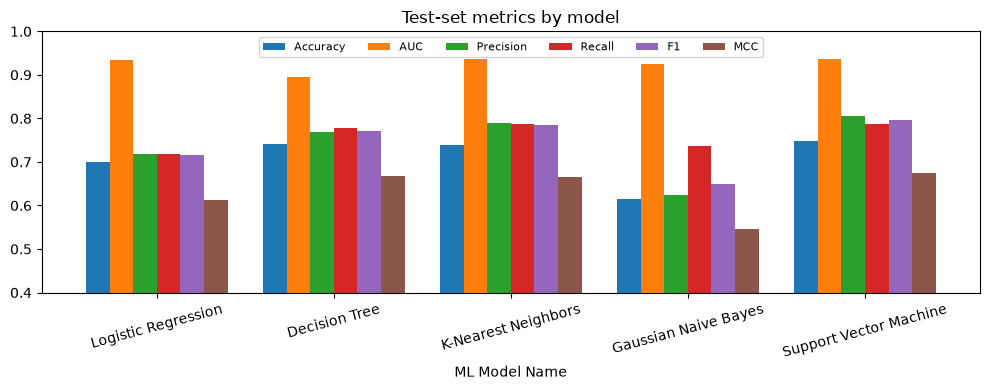

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
results.plot.bar(ax=ax, width=0.8)
ax.set_ylim(0.4, 1.0)
ax.set_title("Test-set metrics by model")
ax.tick_params(axis="x", rotation=15)
ax.legend(ncol=6, fontsize=8, loc="upper center")
plt.tight_layout()
plt.show()

### Over-fitting check (train vs test accuracy)

If a model is much more accurate on the training data than on the test
data, it has memorised the training set instead of learning general
patterns.

In [13]:
fit_gap = pd.DataFrame({
    "train_accuracy": pd.Series(train_accuracy),
    "test_accuracy": results["Accuracy"],
})
fit_gap["gap"] = fit_gap["train_accuracy"] - fit_gap["test_accuracy"]
fit_gap.round(4)

,train_accuracy,test_accuracy,gap
Logistic Regression,0.7487,0.6992,0.0495
Decision Tree,0.9169,0.7404,0.1765
K-Nearest Neighbors,1.0000,0.7378,0.2622
Gaussian Naive Bayes,0.6308,0.6144,0.0164
Support Vector Machine,0.8370,0.7481,0.0889


## 8. Confusion matrices for all five models

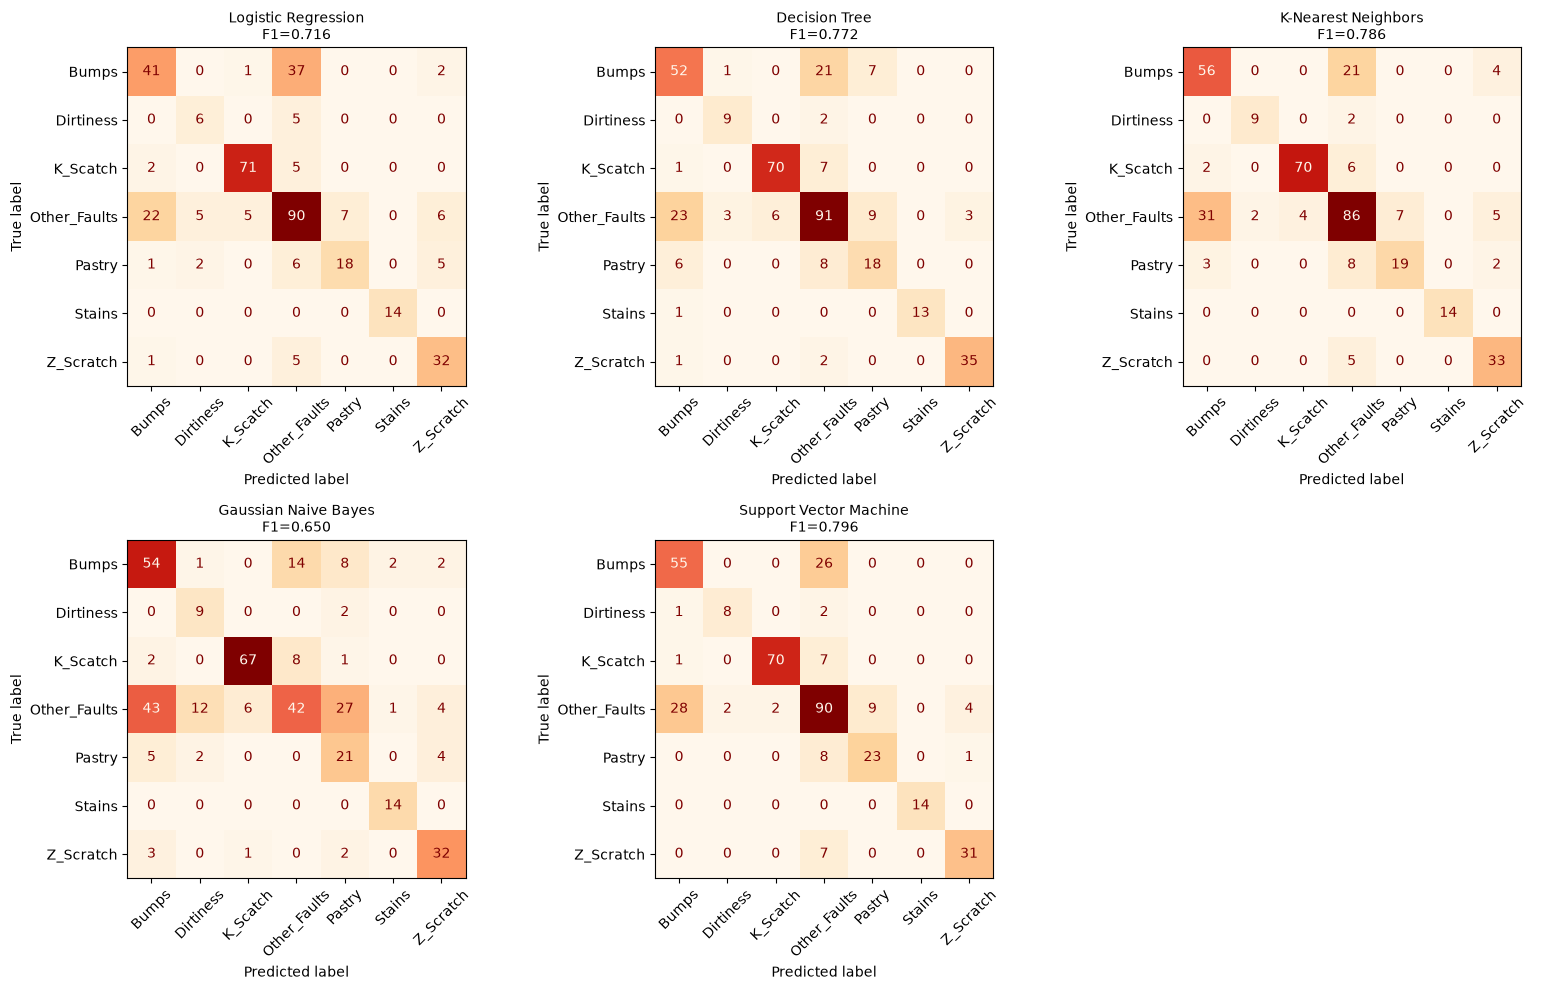

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (name, pred) in zip(axes.ravel(), hold_predictions.items()):
    ConfusionMatrixDisplay(
        confusion_matrix(y_hold, pred, labels=class_ids),
        display_labels=fault_encoder.classes_,
    ).plot(ax=ax, cmap="OrRd", colorbar=False, xticks_rotation=45)
    ax.set_title(f"{name}\nF1={scoreboard[name]['F1']:.3f}", fontsize=10)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

### Per-class F1 and the classification report of the best model

In [15]:
per_class_f1 = pd.DataFrame({
    name: f1_score(y_hold, pred, average=None, labels=class_ids)
    for name, pred in hold_predictions.items()
}, index=fault_encoder.classes_).T.round(3)
per_class_f1

,Bumps,Dirtiness,K_Scatch,Other_Faults,Pastry,Stains,Z_Scratch
Logistic Regression,0.554,0.500,0.916,0.636,0.632,1.000,0.771
Decision Tree,0.630,0.750,0.909,0.684,0.545,0.963,0.921
K-Nearest Neighbors,0.647,0.818,0.921,0.654,0.655,1.000,0.805
Gaussian Naive Bayes,0.574,0.514,0.882,0.422,0.452,0.903,0.800
Support Vector Machine,0.663,0.762,0.933,0.655,0.719,1.000,0.838


In [16]:
best_name = results["MCC"].idxmax()
print("Best model by MCC:", best_name, "\n")
print(classification_report(
    y_hold, hold_predictions[best_name], labels=class_ids,
    target_names=fault_encoder.classes_, digits=4, zero_division=0))

Best model by MCC: Support Vector Machine 

              precision    recall  f1-score   support

       Bumps     0.6471    0.6790    0.6627        81
   Dirtiness     0.8000    0.7273    0.7619        11
    K_Scatch     0.9722    0.8974    0.9333        78
Other_Faults     0.6429    0.6667    0.6545       135
      Pastry     0.7188    0.7188    0.7188        32
      Stains     1.0000    1.0000    1.0000        14
   Z_Scratch     0.8611    0.8158    0.8378        38

    accuracy                         0.7481       389
   macro avg     0.8060    0.7864    0.7956       389
weighted avg     0.7546    0.7481    0.7508       389



## 9. Save the models, label encoder and manifest

In [17]:
for display_name, stem, _, _ in model_specs:
    joblib.dump(tuned_models[display_name],
                ARTIFACT_DIR / f"{stem}.joblib")
joblib.dump(fault_encoder, ARTIFACT_DIR / "fault_label_encoder.joblib")

manifest = {
    "dataset": "UCI Steel Plates Faults (id 198)",
    "target_column": TARGET_COLUMN,
    "feature_columns": feature_names,
    "fault_classes": fault_encoder.classes_.tolist(),
    "seed": SEED,
    "holdout_fraction": HOLDOUT_FRACTION,
    "train_rows": int(len(X_fit)),
    "holdout_rows": int(len(X_hold)),
    "model_files": {name: f"{stem}.joblib"
                    for name, stem, _, _ in model_specs},
    "best_params": chosen_params,
    "holdout_metrics": {
        name: {m: round(float(v), 4) for m, v in vals.items()}
        for name, vals in scoreboard.items()
    },
}
with open(ARTIFACT_DIR / "training_manifest.json", "w") as handle:
    json.dump(manifest, handle, indent=2, default=str)

for path in sorted(ARTIFACT_DIR.iterdir()):
    print(f"{path.name:<30} {path.stat().st_size / 1024:8.1f} KB")

decision_tree.joblib               42.1 KB
fault_label_encoder.joblib          0.5 KB
knn.joblib                        342.1 KB
logistic_regression.joblib          4.2 KB
naive_bayes.joblib                  5.6 KB
svm.joblib                        274.6 KB
training_manifest.json              2.4 KB


### Check: reload the saved files and score `test_data.csv`

This is what the Streamlit app does. It loads the saved models and only
predicts, with no retraining. The numbers must be the same as in the table
above.

In [18]:
check_df = pd.read_csv(HOLDOUT_CSV)
encoder = joblib.load(ARTIFACT_DIR / "fault_label_encoder.joblib")
y_check = encoder.transform(check_df[TARGET_COLUMN])
reloaded = {}
for name, file_name in manifest["model_files"].items():
    model = joblib.load(ARTIFACT_DIR / file_name)
    reloaded[name] = score_predictions(
        y_check, model.predict(check_df[feature_names]),
        model.predict_proba(check_df[feature_names]))
reloaded = pd.DataFrame(reloaded).T.round(4)
assert np.allclose(reloaded.values, results.values)
print("Reloaded models reproduce the test metrics exactly.")
reloaded

Reloaded models reproduce the test metrics exactly.


,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.6992,0.9340,0.7193,0.7190,0.7156,0.6124
Decision Tree,0.7404,0.8940,0.7682,0.7777,0.7719,0.6673
K-Nearest Neighbors,0.7378,0.9376,0.7894,0.7866,0.7858,0.6645
Gaussian Naive Bayes,0.6144,0.9251,0.6244,0.7362,0.6496,0.5452
Support Vector Machine,0.7481,0.9366,0.8060,0.7864,0.7956,0.6750


## 10. Observations

| ML Model Name | Observation about model performance |
|---|---|
| Logistic Regression | A good linear baseline with a high AUC (0.934), but its accuracy (0.699) and MCC (0.612) are the second lowest. Linear boundaries cannot separate **Bumps** from **Other_Faults**. Train and test accuracy are close, so it underfits. |
| Decision Tree | Second-best MCC (0.667) and the best F1 on Z_Scratch and Other_Faults. It has the lowest AUC (0.894) because leaf probabilities are coarse. The train/test gap (0.917 vs 0.740) shows some overfitting. |
| kNN | Best AUC (0.938) and macro recall (0.787), and strong on the small classes. It memorises the training set (train accuracy 1.00) and is the largest and slowest model to predict with. |
| Naive Bayes | The weakest model (accuracy 0.614, MCC 0.545). Correlated and skewed features break its assumptions. It over-predicts Pastry and Dirtiness and misses many Other_Faults plates. |
| SVM | Best accuracy (0.748), precision (0.806), F1 (0.796) and MCC (0.675). Its AUC and recall are within 0.001 of kNN. It has a small train/test gap, so it generalises well. |
| **Overall, Winner for your dataset?** | **SVM (RBF kernel)**: highest MCC, accuracy, precision and F1. kNN is a close second. The hardest pair for every model is **Bumps vs Other_Faults**. |